# Day 2: Descriptive Statistics

Mean, median, mode, variance and standard deviation, first by hand on a tiny list and then on the
house dataset. `houses_raw.csv` is made by `generate_houses.py` (synthetic data, fixed seed).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. A small example worked by hand

In [2]:
marks = np.array([2, 4, 4, 4, 5, 5, 7, 9])

print("Mean   :", marks.mean())
print("Median :", np.median(marks))
print("Mode   :", pd.Series(marks).mode().tolist())

Mean   : 5.0
Median : 4.5
Mode   : [4]


In [3]:
# Variance step by step: deviations -> squares -> sum -> divide
mean = marks.mean()
deviations = marks - mean
squared = deviations ** 2
print("Deviations:", deviations)
print("Squared   :", squared, "| sum =", squared.sum())

pop_var = squared.sum() / len(marks)
samp_var = squared.sum() / (len(marks) - 1)
print(f"Population variance = {pop_var:.2f}, std = {pop_var ** 0.5:.2f}")
print(f"Sample variance     = {samp_var:.2f}, std = {samp_var ** 0.5:.2f}")

Deviations: [-3. -1. -1. -1.  0.  0.  2.  4.]
Squared   : [ 9.  1.  1.  1.  0.  0.  4. 16.] | sum = 32.0
Population variance = 4.00, std = 2.00
Sample variance     = 4.57, std = 2.14


**Watch out:** NumPy divides by n by default (`ddof=0`) while Pandas divides by n - 1 (`ddof=1`).
Same data, different answer, so always check.

In [4]:
print("np.var          :", np.var(marks))
print("pd.Series.var   :", pd.Series(marks).var())
print("np.var(ddof=1)  :", np.var(marks, ddof=1))

np.var          : 4.0
pd.Series.var   : 4.571428571428571
np.var(ddof=1)  : 4.571428571428571


In [5]:
# Why the median matters: one extreme value drags the mean but not the median
with_outlier = marks.copy()
with_outlier[-1] = 90
print("Mean   :", marks.mean(), "->", with_outlier.mean())
print("Median :", np.median(marks), "->", np.median(with_outlier))

Mean   : 5.0 -> 15.125
Median : 4.5 -> 4.5


## 2. The house dataset

In [6]:
df = pd.read_csv("houses_raw.csv")
print(df.shape)
df.head()

(305, 6)


,area_marla,bedrooms,bathrooms,age_years,location_zone,price_million_pkr
0,12.5,5,5.0,11.0,Central,23.58
1,5.5,1,1.0,NaN,Outskirts,5.05
2,10.5,3,2.0,15.0,Central,16.35
3,18.5,4,3.0,23.0,Suburban,23.27
4,11.5,3,2.0,22.0,Suburban,15.20


In [7]:
df.describe().round(2)

,area_marla,bedrooms,bathrooms,age_years,price_million_pkr
count,305.00,305.00,295.00,290.00,305.00
mean,12.56,2.90,2.40,14.46,15.28
std,11.72,1.31,1.28,9.06,5.93
min,3.00,1.00,1.00,0.00,3.32
25%,7.50,2.00,1.00,7.00,10.94
50%,11.50,3.00,2.00,14.00,15.27
75%,15.50,4.00,3.00,22.00,19.31
max,120.00,6.00,5.00,30.00,28.55


In [8]:
price = df["price_million_pkr"]
print(f"Price mean   : {price.mean():.2f}")
print(f"Price median : {price.median():.2f}")
print(f"Price std    : {price.std():.2f}  (Pandas, sample)")
print(f"Price std    : {np.std(price):.2f}  (NumPy, population)")

print("\nMost common bedrooms:", df["bedrooms"].mode().tolist())
print("Most common zone    :", df["location_zone"].mode().tolist())

Price mean   : 15.28
Price median : 15.27
Price std    : 5.93  (Pandas, sample)
Price std    : 5.92  (NumPy, population)

Most common bedrooms: [3]
Most common zone    : ['Suburban']


In [9]:
# area_marla has a few impossible values, look at mean vs median
print("Area mean  :", round(df["area_marla"].mean(), 2))
print("Area median:", df["area_marla"].median())
print("Largest areas:", sorted(df["area_marla"].nlargest(4).tolist()))

Area mean  : 12.56
Area median: 11.5
Largest areas: [20.0, 120.0, 120.0, 120.0]


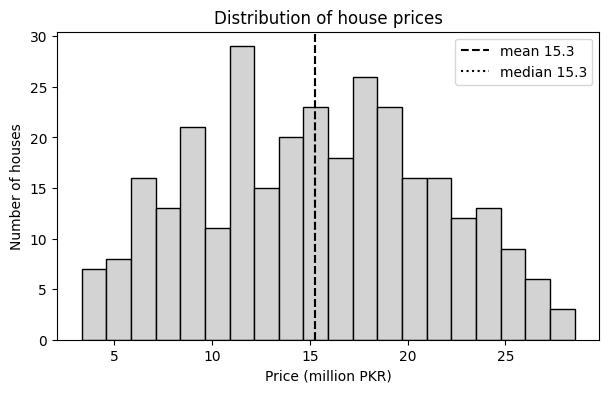

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(price, bins=20, edgecolor="black", color="lightgrey")
ax.axvline(price.mean(), color="black", linestyle="--", label=f"mean {price.mean():.1f}")
ax.axvline(price.median(), color="black", linestyle=":", label=f"median {price.median():.1f}")
ax.set_xlabel("Price (million PKR)")
ax.set_ylabel("Number of houses")
ax.set_title("Distribution of house prices")
ax.legend()
plt.show()

Price looks roughly symmetric, so mean and median are close. Area is a different story: a few
impossible values pull its mean far above its median. That is a cleaning job for Day 4.